# 01 · Exploratory Data Analysis and Data Quality
**Dataset:** Feline Behavior and Personality Survey Data, Mikkola et al. (2021), Figshare, CC BY 4.0.  
**Target:** `fearfulness` factor score, binarised at the *training-set* median (lower vs. higher fear).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from catsense import config as C, data
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 160)

## 1. Loading and structure

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.iloc[:5, :12]

(4316, 151)


,CATID,BREEDGROUP,SEX,AGE_BEHAVIOUR,OTHER_CATS,problematic_behavior,seeks_physical_contact_people,Opens_doors,Rests _in_secure_places,Reacts_to_video_TV,Refuses_litter_box_dirty,Freezes_examined_veterinarian
0,1,Siberian_and_Neva_Masquerade,Female,5.079872,unknown,unknown,5,5.0,3.0,5.0,4.0,5.0
1,2,Sphynx_and_Devon_Rex,Female,4.225506,unknown,unknown,5,5.0,5.0,2.0,1.0,5.0
2,3,Oriental,Female,7.419576,NO,A_little,5,5.0,4.0,4.0,4.0,2.0
3,4,Sphynx_and_Devon_Rex,Female,2,YES,No,5,4.0,4.0,5.0,2.0,1.0
4,5,House_cat,Female,3.535049,YES,A_little,5,1.0,4.0,1.0,5.0,1.0


In [3]:
dictionary = data.load_dictionary()
dictionary.groupby('section').size()

section
Demographic and background information      6
Factor scores                               8
Personality and behavior                  137
dtype: int64

In [4]:
df = data.load_clean()
items = data.item_columns(df)
print(f'{len(df)} cats, {len(items)} survey items, {len(C.TRAIT_SCORES)} trait scores, '
      f'{len(C.DEMOGRAPHIC_CATEGORICAL) + 1} demographic columns')
df[items].stack().value_counts().sort_index()  # Likert answers 1-5

4316 cats, 138 survey items, 7 trait scores, 5 demographic columns


1.0    198487
2.0     72311
3.0     31139
4.0    103849
5.0    121828
Name: count, dtype: int64

## 2. Data quality
### 2.1 Duplicates and inconsistent headers

In [5]:
print('Duplicate CATIDs:', raw['CATID'].duplicated().sum())
print('Duplicate rows (ignoring CATID):', raw.drop(columns='CATID').duplicated().sum())
print('Headers with stray spaces:', [c for c in raw.columns if c != c.strip() or ' ' in c])

Duplicate CATIDs: 0
Duplicate rows (ignoring CATID): 0
Headers with stray spaces: ['Rests _in_secure_places', 'easily_scared_things_sounds ', 'Unexpectedly_scratches _bites', 'Runs_ hides_noise_inside', 'Asks_in_out_ rooms', 'Freezes_nothing visible', 'Growls_ hisses_bathed', 'excessive_ grooming', 'Gets_along _with_cats', 'scratch_bite _medicine_familiar_person', 'meowing _left_alone', 'Squirms_picked_ held_arms', 'comfortable_playing _unfamiliar_people']


Thirteen headers contain stray spaces, and the survey item `excessive_ grooming` collides with the trait score `excessive_grooming` once spaces are removed. `data.clean_column` normalises the names and renames the item to `excessive_grooming_item`.

### 2.2 Missing values and 'unknown' codes

In [6]:
miss = data.missing_report(df[items])
print((miss.missing_fraction > C.MAX_MISSING_FRACTION).sum(), 'items exceed', C.MAX_MISSING_FRACTION)
miss.head(15)

13 items exceed 0.4


,missing_fraction,missing_count
baby_cry_check,0.861909,3720
Brings_prey_animals,0.829240,3579
substrate_preference_inappro,0.770621,3326
exited_other_pets,0.752780,3249
Concentration_not_disturbed,0.667980,2883
responds_commands,0.656163,2832
greets_kittens,0.631140,2724
scratch_bite_unfamiliar_dogs,0.571131,2465
Growls_hisses_familiar_dogs,0.527108,2275
scratch_bite_familiar_dogs,0.519462,2242


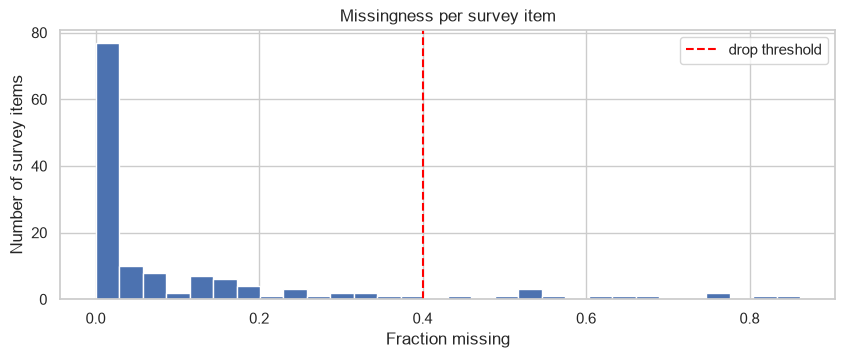

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(miss.missing_fraction, bins=30, color='#4C72B0')
ax.axvline(C.MAX_MISSING_FRACTION, color='red', ls='--', label='drop threshold')
ax.set(xlabel='Fraction missing', ylabel='Number of survey items', title='Missingness per survey item')
ax.legend()
fig.savefig(C.FIGURES / 'eda_missingness.png', dpi=150, bbox_inches='tight')

In [8]:
print(data.unknown_report(df))
print('AGE missing ("unknown"):', df.AGE_BEHAVIOUR.isna().sum())
both = ((df.OTHER_CATS == 'unknown') & (df.problematic_behavior == 'unknown')).sum()
print('Rows where both OTHER_CATS and problematic_behavior are unknown:', both)

BREEDGROUP                0
SEX                       0
OTHER_CATS              997
problematic_behavior    997
dtype: int64
AGE missing ("unknown"): 123
Rows where both OTHER_CATS and problematic_behavior are unknown: 997


Missing item answers are mostly questions that do not apply to every household (e.g. behaviour towards dogs, kittens or babies). Items with more than 40% missing are dropped; remaining gaps are median-imputed **inside the pipeline** with a missing-indicator column, fitted on training folds only. The 997 rows with `unknown` for both `OTHER_CATS` and `problematic_behavior` appear to come from an earlier survey version; `unknown` is kept as its own category instead of being dropped.

### 2.3 Outliers

Age IQR outliers: 6 | max age 22.7


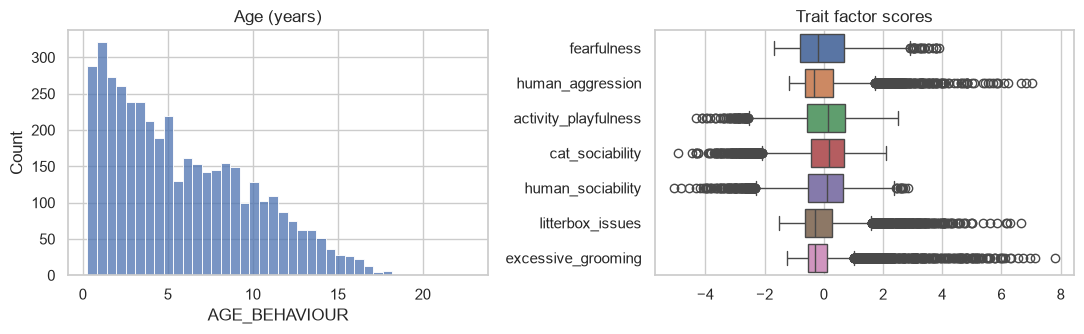

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df.AGE_BEHAVIOUR, bins=40, ax=axes[0]); axes[0].set_title('Age (years)')
sns.boxplot(data=df[C.TRAIT_SCORES], orient='h', ax=axes[1]); axes[1].set_title('Trait factor scores')
fig.tight_layout(); fig.savefig(C.FIGURES / 'eda_outliers.png', dpi=150)
q1, q3 = df.AGE_BEHAVIOUR.quantile([.25, .75]); iqr = q3 - q1
print('Age IQR outliers:', (df.AGE_BEHAVIOUR > q3 + 1.5 * iqr).sum(), '| max age', df.AGE_BEHAVIOUR.max().round(1))

Age outliers (cats up to ~22.7 years) are biologically plausible, so they are kept. Aggression, litterbox and grooming scores are strongly right-skewed (few cats with problems), but they are *not* used as features.

## 3. Target: fearfulness

In [10]:
train, test, threshold = data.split(df)
print(f'Training median threshold = {threshold:.4f}')
print(pd.DataFrame({'train': train[C.TARGET].value_counts(), 'test': test[C.TARGET].value_counts()}))

Training median threshold = -0.1996
           train  test
high_fear             
1           1726   435
0           1726   429


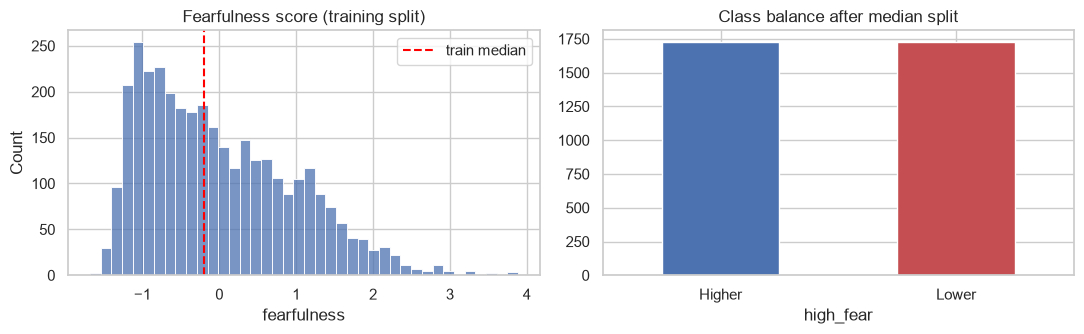

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train.fearfulness, bins=40, ax=axes[0]); axes[0].axvline(threshold, color='red', ls='--', label='train median')
axes[0].set_title('Fearfulness score (training split)'); axes[0].legend()
train[C.TARGET].map({0: 'Lower', 1: 'Higher'}).value_counts().plot.bar(ax=axes[1], color=['#4C72B0', '#C44E52'], rot=0)
axes[1].set_title('Class balance after median split')
fig.tight_layout(); fig.savefig(C.FIGURES / 'eda_target.png', dpi=150)

The median split yields balanced classes (50/50), so accuracy is meaningful, but macro-F1 is still reported.

## 4. Demographics vs. fearfulness (training split only)

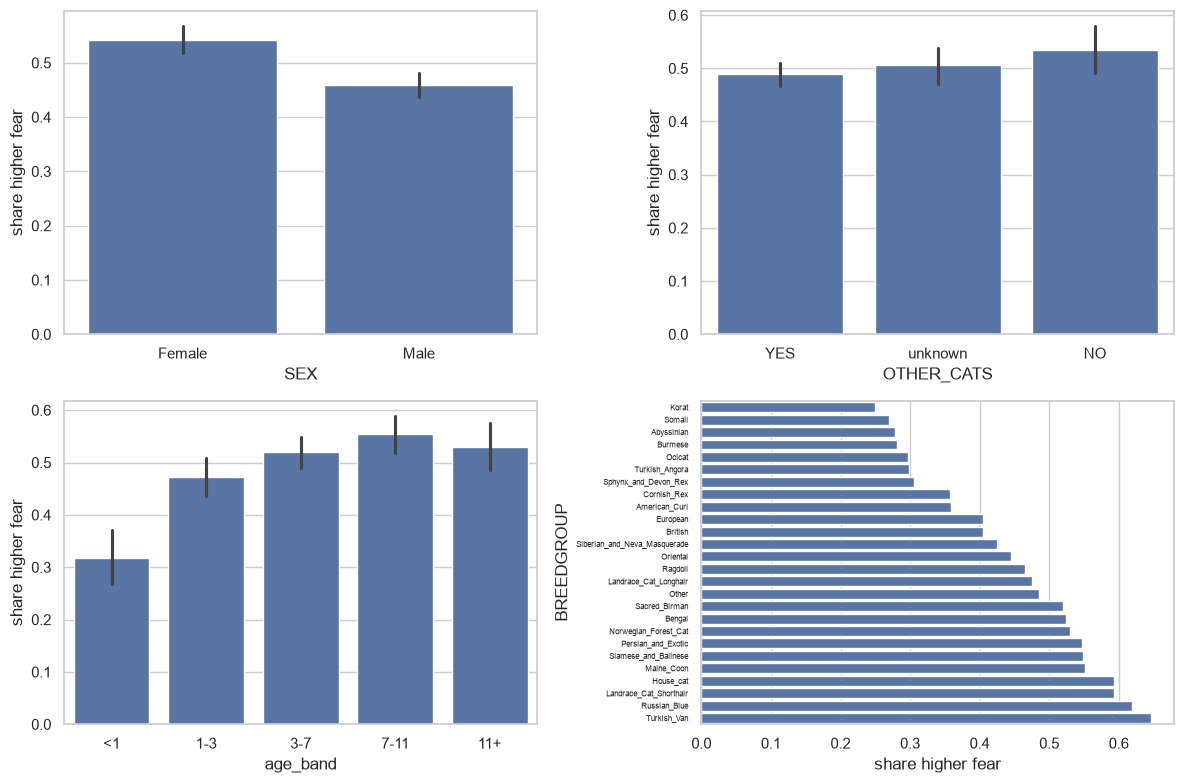

In [12]:
t = train.assign(age_band=data.age_band(train.AGE_BEHAVIOUR))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat[:3], ['SEX', 'OTHER_CATS', 'age_band']):
    sns.barplot(data=t, x=col, y=C.TARGET, ax=ax, errorbar=('ci', 95)); ax.set_ylabel('share higher fear')
order = t.groupby('BREEDGROUP')[C.TARGET].mean().sort_values().index
sns.barplot(data=t, y='BREEDGROUP', x=C.TARGET, order=order, ax=axes[1, 1], errorbar=None)
axes[1, 1].tick_params(axis='y', labelsize=6); axes[1, 1].set_xlabel('share higher fear')
fig.tight_layout(); fig.savefig(C.FIGURES / 'eda_demographics.png', dpi=150)

## 5. Behaviour items vs. fearfulness and leakage check

In [13]:
corr = train[items].corrwith(train.fearfulness).sort_values(key=abs, ascending=False)
leak = pd.DataFrame({'corr_with_fearfulness': corr, 'fear_item (excluded)': corr.index.isin(C.FEAR_ITEMS)})
leak.head(25)

,corr_with_fearfulness,fear_item (excluded)
Escapes_unfamiliar_people,0.827684,True
comfortable_social_gatherings,-0.819387,True
greets_unfamiliar_adults,-0.806695,True
comfortable_petted_unfamiliar_people,-0.804769,True
comfortable_playing_unfamiliar_people,-0.794216,True
not_approach_people_right_away,0.756385,True
greets_unfamiliar_children,-0.736801,True
comfortable_unfamiliar_places,-0.610048,True
easily_scared_things_sounds,0.555866,True
Runs_hides_noise_inside,0.554790,True


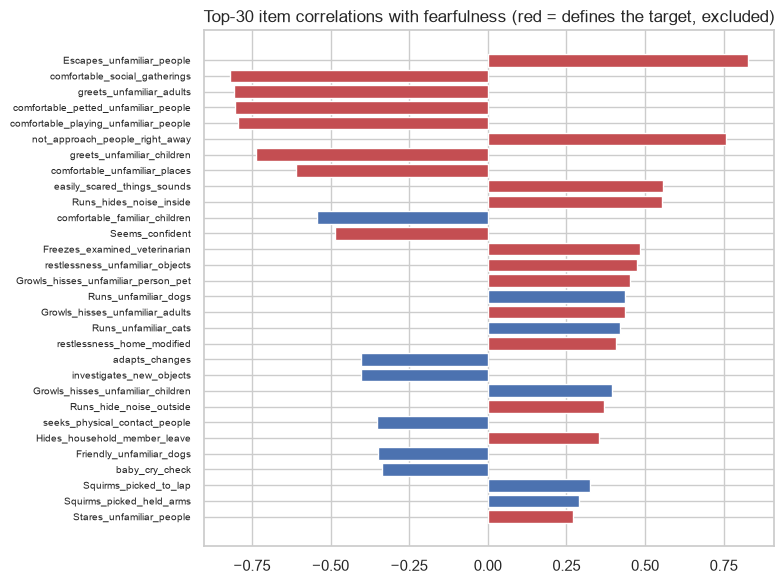

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
top = leak.head(30).iloc[::-1]
ax.barh(top.index, top.corr_with_fearfulness, color=np.where(top['fear_item (excluded)'], '#C44E52', '#4C72B0'))
ax.set_title('Top-30 item correlations with fearfulness (red = defines the target, excluded)')
ax.tick_params(axis='y', labelsize=7); fig.tight_layout(); fig.savefig(C.FIGURES / 'eda_item_correlations.png', dpi=150)

The 19 items that load on the Fearfulness factor in Mikkola et al. (2021, Table 1) dominate the correlations (|r| up to 0.83). They are removed from all feature sets. The other six trait scores are also excluded because they are computed with the tenBerge method from the same item responses.

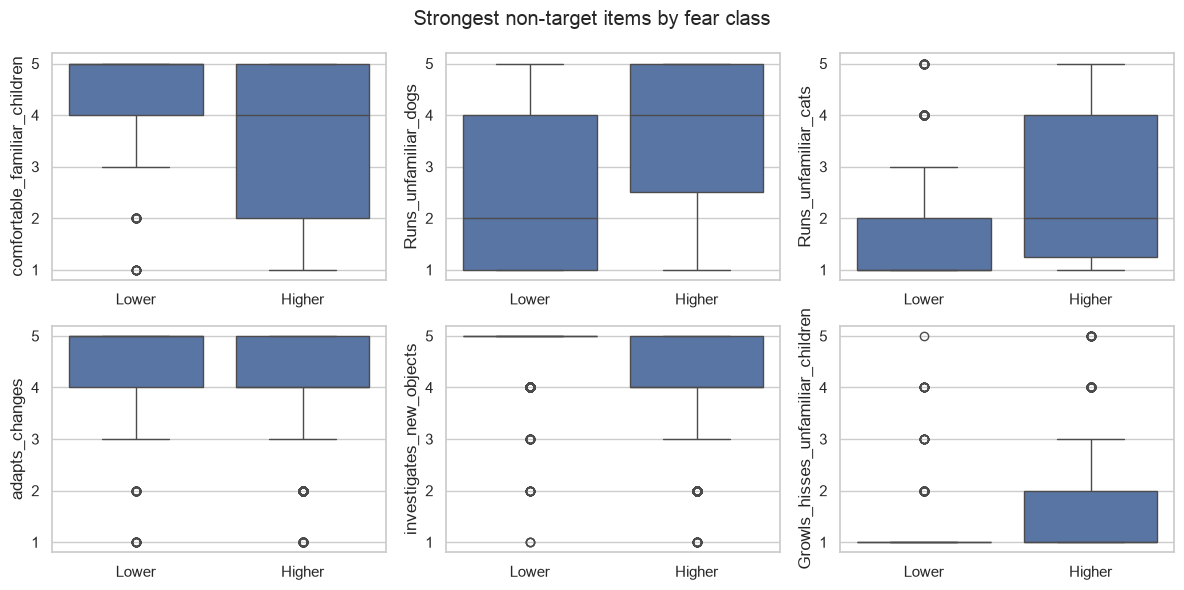

In [15]:
keep = [c for c in items if c not in C.FEAR_ITEMS]
top_keep = corr[keep].abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, top_keep):
    sns.boxplot(data=train, x=C.TARGET, y=col, ax=ax); ax.set_xticklabels(['Lower', 'Higher']); ax.set_xlabel('')
fig.suptitle('Strongest non-target items by fear class'); fig.tight_layout()
fig.savefig(C.FIGURES / 'eda_boxplots.png', dpi=150)

### Correlation between candidate predictors (multicollinearity)

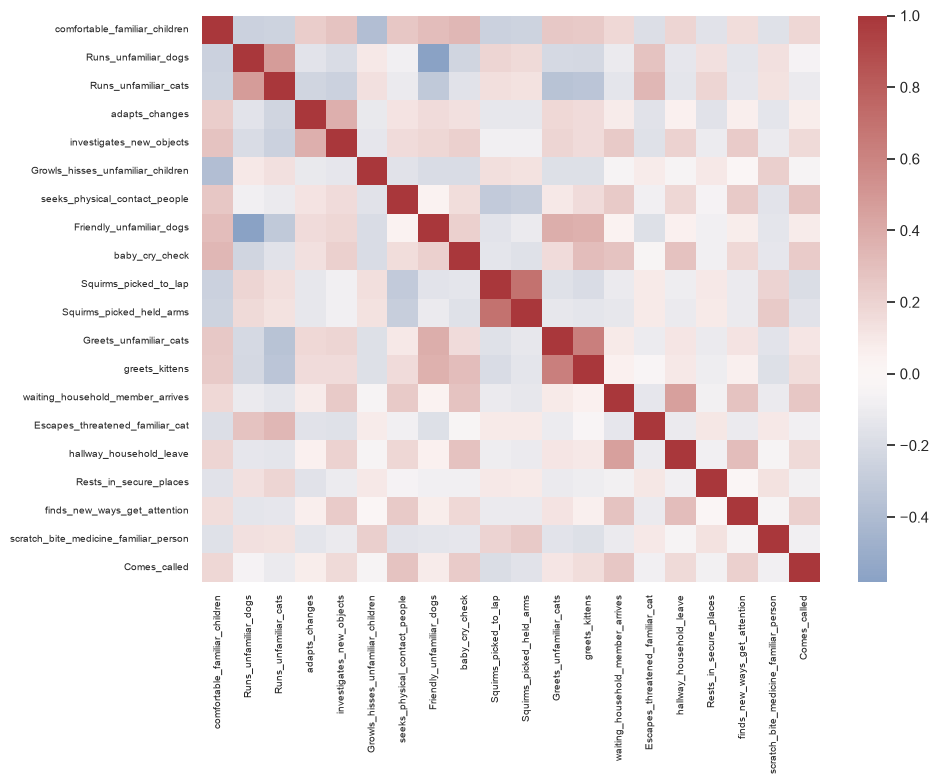

In [16]:
sel = corr[keep].abs().sort_values(ascending=False).index[:20]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train[list(sel)].corr(), cmap='vlag', center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7); fig.tight_layout(); fig.savefig(C.FIGURES / 'eda_heatmap.png', dpi=150)

## 6. Summary of decisions
| Finding | Decision |
|---|---|
| 0 duplicate rows / IDs | nothing removed |
| 13 messy headers, 1 name collision | normalised, item renamed |
| 13 items > 40% missing (not applicable questions) | dropped |
| remaining missing answers | median + missing indicator, fitted on train folds |
| 997 `unknown` in two demographics, 123 unknown ages | `unknown` kept as category; age median-imputed |
| plausible age outliers | kept |
| 19 target-defining items + 6 other factor scores | excluded (leakage) |
| balanced target after median split | stratified split, macro-F1 + AUC reported |
| Likert scales differ in spread | standardised for Logistic Regression only |